# Experiment 2 – Understanding Loss Functions (MSE vs BCE)
**Course:** Foundations of Deep Learning  
**Name:** Acchute Kashyap  
**Reg. No:** CH.SC.U4CSE23003  
**Date:** 16th October 2026

**Objective:** Compare Mean Squared Error (MSE) and Binary Cross Entropy (BCE) for binary classification.

## Cell 1 – Setup

In [9]:
import math
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 7                       # one seed for the whole experiment (reproducibility)
tf.keras.utils.set_random_seed(SEED)

pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print("TensorFlow version :", tf.__version__)
print("Random seed        :", SEED)

TensorFlow version : 2.18.0
Random seed        : 7


---
## Task 11 – Mean Squared Error (manual calculation)

**Given**

$$y = [1,\;1,\;0,\;0] \qquad \hat{y} = [0.95,\;0.80,\;0.30,\;0.10]$$

**Formula**

$$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n}\left(y_i-\hat{y}_i\right)^2$$

Step 1 → error of every sample, Step 2 → square it, Step 3 → add up, Step 4 → divide by $n$.

In [10]:
# ---------- Cell 2 : Task 11 – manual MSE (no library maths, plain Python loop) ----------
y_true   = [1, 1, 0, 0]
y_pred_A = [0.95, 0.80, 0.30, 0.10]

rows = []
sum_sq = 0.0
for i, (yt, yp) in enumerate(zip(y_true, y_pred_A), start=1):
    err = yt - yp
    sq  = err ** 2
    sum_sq += sq
    rows.append({"Sample": i, "y (true)": yt, "ŷ (pred)": yp,
                 "Error (y − ŷ)": err, "Squared error": sq})

table_11 = pd.DataFrame(rows).set_index("Sample")
display(table_11)

n = len(y_true)
mse_A = sum_sq / n
terms = " + ".join(f"{r['Squared error']:.4f}" for r in rows)
print(f"Sum of squared errors = {terms} = {sum_sq:.4f}")
print(f"MSE = {sum_sq:.4f} / {n} = {mse_A:.6f}")

# ---------- verification with NumPy ----------
print("\nVerification (NumPy) :", np.mean((np.array(y_true) - np.array(y_pred_A)) ** 2))

,y (true),ŷ (pred),Error (y − ŷ),Squared error
Sample,,,,
1,1,0.9500,0.0500,0.0025
2,1,0.8000,0.2000,0.0400
3,0,0.3000,-0.3000,0.0900
4,0,0.1000,-0.1000,0.0100


Sum of squared errors = 0.0025 + 0.0400 + 0.0900 + 0.0100 = 0.1425
MSE = 0.1425 / 4 = 0.035625

Verification (NumPy) : 0.035625


---
## Task 12 – Binary Cross Entropy (manual calculation)

**Formula**

$$\text{BCE} = -\frac{1}{n}\sum_{i=1}^{n}\Big[y_i\ln(\hat{y}_i) + (1-y_i)\ln(1-\hat{y}_i)\Big]$$

Because $y_i$ is either 0 or 1, only **one** of the two terms is active for each sample:

* if $y_i = 1$  →  loss $= -\ln(\hat{y}_i)$
* if $y_i = 0$  →  loss $= -\ln(1-\hat{y}_i)$

In [11]:
# ---------- Cell 3 : Task 12 – manual BCE ----------
rows = []
sum_bce = 0.0
for i, (yt, yp) in enumerate(zip(y_true, y_pred_A), start=1):
    if yt == 1:
        used, term = f"−ln({yp:.2f})",       -math.log(yp)
    else:
        used, term = f"−ln(1−{yp:.2f}) = −ln({1-yp:.2f})", -math.log(1 - yp)
    sum_bce += term
    rows.append({"Sample": i, "y (true)": yt, "ŷ (pred)": yp,
                 "Term used": used, "BCE term": term})

table_12 = pd.DataFrame(rows).set_index("Sample")
display(table_12)

bce_A = sum_bce / n
terms = " + ".join(f"{r['BCE term']:.4f}" for r in rows)
print(f"Sum of BCE terms = {terms} = {sum_bce:.4f}")
print(f"BCE = {sum_bce:.4f} / {n} = {bce_A:.6f}")

# ---------- verification with Keras' built-in loss ----------
keras_bce = tf.keras.losses.BinaryCrossentropy()(
    np.asarray(y_true, dtype=np.float32),
    np.asarray(y_pred_A, dtype=np.float32)
).numpy()
print("\nVerification (tf.keras BinaryCrossentropy) :", round(float(keras_bce), 6))

,y (true),ŷ (pred),Term used,BCE term
Sample,,,,
1,1,0.9500,−ln(0.95),0.0513
2,1,0.8000,−ln(0.80),0.2231
3,0,0.3000,−ln(1−0.30) = −ln(0.70),0.3567
4,0,0.1000,−ln(1−0.10) = −ln(0.90),0.1054


Sum of BCE terms = 0.0513 + 0.2231 + 0.3567 + 0.1054 = 0.7365
BCE = 0.7365 / 4 = 0.184118

Verification (tf.keras BinaryCrossentropy) : 0.184118


---
## Task 13 – Repeat the calculations for $\hat{y} = [0.60,\;0.55,\;0.45,\;0.40]$

The same steps are wrapped in a reusable function, so both loss functions are computed for the new predictions in one go.

In [12]:
# ---------- Cell 4 : Task 13 – same calculation for the second set of predictions ----------
def manual_losses(y_t, y_p, title):
    rows, s_sq, s_bce = [], 0.0, 0.0
    for i, (yt, yp) in enumerate(zip(y_t, y_p), start=1):
        sq  = (yt - yp) ** 2
        bce = -math.log(yp) if yt == 1 else -math.log(1 - yp)
        s_sq += sq;  s_bce += bce
        rows.append({"Sample": i, "y (true)": yt, "ŷ (pred)": yp,
                     "Error": yt - yp, "Squared error": sq, "BCE term": bce})
    print(title)
    display(pd.DataFrame(rows).set_index("Sample"))
    m = s_sq / len(y_t);  b = s_bce / len(y_t)
    print(f"Sum of squared errors = {s_sq:.4f}   ->  MSE = {s_sq:.4f}/{len(y_t)} = {m:.6f}")
    print(f"Sum of BCE terms      = {s_bce:.4f}   ->  BCE = {s_bce:.4f}/{len(y_t)} = {b:.6f}")
    return m, b

y_pred_B = [0.60, 0.55, 0.45, 0.40]
mse_B, bce_B = manual_losses(y_true, y_pred_B, "Predictions B = [0.60, 0.55, 0.45, 0.40]")

# quick sanity check that the function reproduces Tasks 11 & 12
print("\nSanity check on set A:", np.isclose(manual_losses(y_true, y_pred_A, "(re-run on set A)")[0], mse_A))

Predictions B = [0.60, 0.55, 0.45, 0.40]


,y (true),ŷ (pred),Error,Squared error,BCE term
Sample,,,,,
1,1,0.6000,0.4000,0.1600,0.5108
2,1,0.5500,0.4500,0.2025,0.5978
3,0,0.4500,-0.4500,0.2025,0.5978
4,0,0.4000,-0.4000,0.1600,0.5108


Sum of squared errors = 0.7250   ->  MSE = 0.7250/4 = 0.181250
Sum of BCE terms      = 2.2173   ->  BCE = 2.2173/4 = 0.554331
(re-run on set A)


,y (true),ŷ (pred),Error,Squared error,BCE term
Sample,,,,,
1,1,0.9500,0.0500,0.0025,0.0513
2,1,0.8000,0.2000,0.0400,0.2231
3,0,0.3000,-0.3000,0.0900,0.3567
4,0,0.1000,-0.1000,0.0100,0.1054


Sum of squared errors = 0.1425   ->  MSE = 0.1425/4 = 0.035625
Sum of BCE terms      = 0.7365   ->  BCE = 0.7365/4 = 0.184118

Sanity check on set A: True


---
## Task 14 – Compare the values

,Predicted probabilities,MSE,BCE,MSE increase (×),BCE increase (×)
Set A (confident),"[0.95, 0.80, 0.30, 0.10]",0.0356,0.1841,1.0000,1.0000
Set B (uncertain),"[0.60, 0.55, 0.45, 0.40]",0.1812,0.5543,5.0877,3.0107


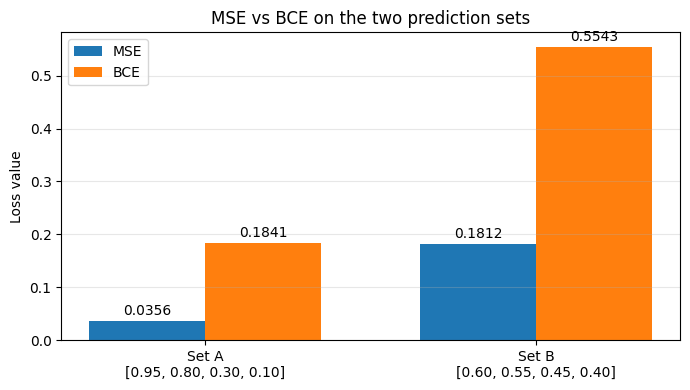

Set A: accuracy at threshold 0.5 = 100%
Set B: accuracy at threshold 0.5 = 100%


In [13]:
# ---------- Cell 5 : Task 14 – comparison table + bar chart ----------
comparison = pd.DataFrame({
    "Predicted probabilities": ["[0.95, 0.80, 0.30, 0.10]", "[0.60, 0.55, 0.45, 0.40]"],
    "MSE": [mse_A, mse_B],
    "BCE": [bce_A, bce_B],
})
comparison["MSE increase (×)"] = comparison["MSE"] / comparison["MSE"].iloc[0]
comparison["BCE increase (×)"] = comparison["BCE"] / comparison["BCE"].iloc[0]
comparison.index = ["Set A (confident)", "Set B (uncertain)"]
display(comparison)

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(2); w = 0.35
b1 = ax.bar(x - w/2, [mse_A, mse_B], w, label="MSE")
b2 = ax.bar(x + w/2, [bce_A, bce_B], w, label="BCE")
ax.bar_label(b1, fmt="%.4f", padding=2); ax.bar_label(b2, fmt="%.4f", padding=2)
ax.set_xticks(x); ax.set_xticklabels(["Set A\n[0.95, 0.80, 0.30, 0.10]", "Set B\n[0.60, 0.55, 0.45, 0.40]"])
ax.set_ylabel("Loss value"); ax.set_title("MSE vs BCE on the two prediction sets")
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

# do both sets classify every sample correctly at the 0.5 threshold?
for name, p in [("A", y_pred_A), ("B", y_pred_B)]:
    acc = np.mean((np.array(p) > 0.5).astype(int) == np.array(y_true))
    print(f"Set {name}: accuracy at threshold 0.5 = {acc*100:.0f}%")

### Observations (Task 14)

* **Set A** (confident, correct predictions) gives **MSE = 0.0356** and **BCE = 0.1841**.
* **Set B** (hesitant predictions near 0.5) gives **MSE = 0.1813** and **BCE = 0.5543**.
* Both losses **rise** when the model becomes less sure of itself — MSE grows about **5.1×**, BCE about **3.0×**.
* Notice that *every* prediction in Set B is still on the correct side of 0.5 (100 % accuracy), yet the loss is much higher. 
  Loss measures **how confident and how close** the probabilities are to the truth, not just whether the thresholded label is right.
* For the same predictions BCE is always numerically larger than MSE, because $-\ln(p)$ grows without bound as $p \to 0$, whereas a squared error can never exceed 1.

---
## Task 15 – Why does BCE give stronger gradients for classification?

Let the output neuron be $a = \sigma(z) = \dfrac{1}{1+e^{-z}}$, whose derivative is $\dfrac{da}{dz}=a(1-a)$.

**MSE (single sample)**

$$L_{MSE} = (a-y)^2 \;\;\Rightarrow\;\; \frac{\partial L}{\partial z} = 2(a-y)\cdot \underbrace{a(1-a)}_{\text{sigmoid slope}}$$

**BCE (single sample)**

$$L_{BCE} = -\big[y\ln a + (1-y)\ln(1-a)\big] \;\;\Rightarrow\;\; \frac{\partial L}{\partial z} = \frac{a-y}{a(1-a)}\cdot a(1-a) = a-y$$

**Key point:** in BCE the sigmoid slope $a(1-a)$ **cancels out**. In MSE it stays as a multiplier.
When a neuron is *saturated and wrong* (e.g. $y=1$ but $a\approx 0.01$), $a(1-a)\approx 0.01$, so the MSE gradient almost vanishes
and learning stalls exactly when the model needs the biggest correction. The BCE gradient is simply the prediction error $a-y$, which is large when the error is large.

The cell below shows this numerically for a sample whose true label is $y = 1$.

True label y = 1  (the smaller 'a' is, the more wrong the model is)


,|dL/dz| MSE,|dL/dz| BCE,BCE / MSE ratio
Prediction a,,,
0.0100,0.0196,0.9900,50.5051
0.0500,0.0902,0.9500,10.5263
0.1000,0.1620,0.9000,5.5556
0.2500,0.2812,0.7500,2.6667
0.5000,0.2500,0.5000,2.0000
0.7500,0.0938,0.2500,2.6667
0.9000,0.0180,0.1000,5.5556


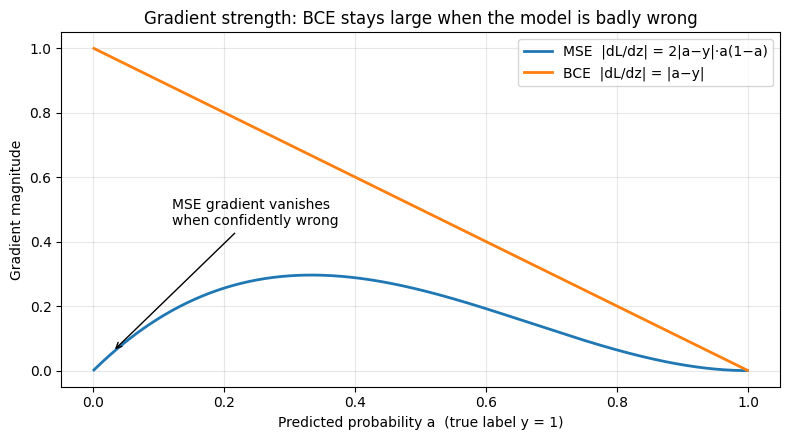

In [14]:
# ---------- Cell 6 : Task 15 – gradient of the loss w.r.t. the pre-activation z (true label y = 1) ----------
a = np.linspace(0.001, 0.999, 500)          # predicted probability
y1 = 1.0
grad_mse = 2 * (a - y1) * a * (1 - a)       # dL/dz for MSE
grad_bce = (a - y1)                          # dL/dz for BCE

sample_a = np.array([0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90])
demo = pd.DataFrame({
    "Prediction a": sample_a,
    "|dL/dz|  MSE": np.abs(2 * (sample_a - 1) * sample_a * (1 - sample_a)),
    "|dL/dz|  BCE": np.abs(sample_a - 1),
})
demo["BCE / MSE ratio"] = demo["|dL/dz|  BCE"] / demo["|dL/dz|  MSE"]
print("True label y = 1  (the smaller 'a' is, the more wrong the model is)")
display(demo.set_index("Prediction a"))

plt.figure(figsize=(8, 4.5))
plt.plot(a, np.abs(grad_mse), linewidth=2, label="MSE  |dL/dz| = 2|a−y|·a(1−a)")
plt.plot(a, np.abs(grad_bce), linewidth=2, label="BCE  |dL/dz| = |a−y|")
plt.xlabel("Predicted probability a  (true label y = 1)")
plt.ylabel("Gradient magnitude")
plt.title("Gradient strength: BCE stays large when the model is badly wrong")
plt.annotate("MSE gradient vanishes\nwhen confidently wrong", xy=(0.03, 0.06), xytext=(0.12, 0.45),
             arrowprops=dict(arrowstyle="->"))
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### Explanation (Task 15)

1. **Gradient formulas.** For a sigmoid output, $\partial L/\partial z = 2(a-y)\,a(1-a)$ for MSE but only $a-y$ for BCE.
2. **Vanishing gradient in MSE.** The extra factor $a(1-a)$ tends to 0 when $a\to0$ or $a\to1$. A confidently *wrong* prediction therefore receives a tiny update — the table above shows the MSE gradient is ≈ 50× weaker than BCE at $a=0.01$.
3. **BCE keeps the signal.** Its gradient is proportional to the actual error, so a badly wrong prediction produces a large corrective step and a correct one produces a small step.
4. **Probabilistic reasoning.** BCE is the negative log-likelihood of a Bernoulli model, so it is the natural loss for probabilities and (for a sigmoid output) gives a smooth, well-behaved loss surface.

Hence BCE gives faster and more reliable learning for classification, whereas MSE is better suited to regression.

---
## Task 16 – Train two identical networks: Model A (MSE) and Model B (BCE)

**Dataset:** XOR (4 samples) — a small non-linear problem that needs a hidden layer.

**Architecture (identical for both models):** `2 inputs → 4 hidden neurons (tanh) → 1 output neuron (sigmoid)`  
**Optimizer:** plain SGD, learning rate 0.5 (so that the *only* thing that differs is the loss function; adaptive optimizers like Adam would partly hide the gradient effect from Task 15)  
**Training:** 1000 epochs, full batch (batch size 4)

To make the two models *truly* identical, the random seed is reset before each model is built, so both start from exactly the same initial weights.

In [15]:
# ---------- Cell 7 : Task 16 – dataset and model builder ----------
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype="float32")
y = np.array([[0], [1], [1], [0]], dtype="float32")

EPOCHS, LR = 1000, 0.5

def build_model(loss_name, seed=SEED):
    tf.keras.utils.set_random_seed(seed)           # same seed -> same initial weights
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(2,)),
        tf.keras.layers.Dense(4, activation="tanh"),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=LR),
                  loss=loss_name, metrics=["accuracy"])
    return model

model_A = build_model("mean_squared_error")        # Model A  (MSE)
model_B = build_model("binary_crossentropy")       # Model B  (BCE)

same_init = all(np.allclose(wa, wb) for wa, wb in zip(model_A.get_weights(), model_B.get_weights()))
print("Both models start from identical weights:", same_init)
model_A.summary()

Both models start from identical weights: True


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17 (68.00 B)

 Trainable params: 17 (68.00 B)

 Non-trainable params: 0 (0.00 B)

In [16]:
# ---------- Cell 8 : Task 16 – train Model A (MSE) and Model B (BCE) ----------
t0 = time.time()
hist_A = model_A.fit(X, y, epochs=EPOCHS, batch_size=4, verbose=0)
time_A = time.time() - t0
print(f"Model A (MSE) trained in {time_A:.1f} s")

t0 = time.time()
hist_B = model_B.fit(X, y, epochs=EPOCHS, batch_size=4, verbose=0)
time_B = time.time() - t0
print(f"Model B (BCE) trained in {time_B:.1f} s")

print("\nLoss after epoch 1   ->  A:", round(hist_A.history['loss'][0], 4), "| B:", round(hist_B.history['loss'][0], 4))
print("Loss after epoch 1000 ->  A:", round(hist_A.history['loss'][-1], 4), "| B:", round(hist_B.history['loss'][-1], 4))

Model A (MSE) trained in 21.6 s
Model B (BCE) trained in 20.9 s

Loss after epoch 1   ->  A: 0.2534 | B: 0.7007
Loss after epoch 1000 ->  A: 0.0019 | B: 0.0051


---
## Task 17 – Compare training loss, accuracy and convergence speed

In [17]:
# ---------- Cell 9 : Task 17 – final metrics, predictions, comparison table ----------
def epochs_to(history_values, condition):
    # first epoch (1-indexed) at which condition(value) is True, else None
    for ep, v in enumerate(history_values, start=1):
        if condition(v):
            return ep
    return None

def summarize(name, model, hist):
    loss_hist = np.array(hist.history["loss"])
    acc_hist  = np.array(hist.history["accuracy"])
    p = model.predict(X, verbose=0).ravel()
    final_loss, final_acc = model.evaluate(X, y, verbose=0)
    return {
        "Model": name,
        "Initial loss (epoch 1)": loss_hist[0],
        "Final training loss": final_loss,
        "Final accuracy (%)": final_acc * 100,
        "Epochs to 100% accuracy": epochs_to(acc_hist, lambda a: a >= 1.0),
        "Epochs to cut loss by 90%": epochs_to(loss_hist, lambda l: l <= 0.1 * loss_hist[0]),
        "Training time (s)": time_A if name.startswith("A") else time_B,
    }, p

sum_A, pred_A = summarize("A (MSE)", model_A, hist_A)
sum_B, pred_B = summarize("B (BCE)", model_B, hist_B)

results = pd.DataFrame([sum_A, sum_B]).set_index("Model")
print("=== Comparison table ===")
display(results.T)

print("\n=== Predicted probabilities on XOR ===")
pred_table = pd.DataFrame({
    "x1": X[:, 0].astype(int), "x2": X[:, 1].astype(int), "y (true)": y.ravel().astype(int),
    "Model A (MSE)": pred_A, "Model B (BCE)": pred_B,
})
display(pred_table)

# Fair cross-check: evaluate BOTH models with BOTH loss functions
mse_fn, bce_fn = tf.keras.losses.MeanSquaredError(), tf.keras.losses.BinaryCrossentropy()
cross = pd.DataFrame({
    "MSE on training data": [mse_fn(y, pred_A.reshape(-1,1)).numpy(), mse_fn(y, pred_B.reshape(-1,1)).numpy()],
    "BCE on training data": [bce_fn(y, pred_A.reshape(-1,1)).numpy(), bce_fn(y, pred_B.reshape(-1,1)).numpy()],
}, index=["Model A (MSE)", "Model B (BCE)"])
print("\n=== Both models scored with both losses (like-for-like) ===")
display(cross)

=== Comparison table ===


Model,A (MSE),B (BCE)
Initial loss (epoch 1),0.2534,0.7007
Final training loss,0.0018,0.0051
Final accuracy (%),100.0000,100.0000
Epochs to 100% accuracy,77.0000,42.0000
Epochs to cut loss by 90%,225.0000,149.0000
Training time (s),21.5521,20.8968



=== Predicted probabilities on XOR ===


,x1,x2,y (true),Model A (MSE),Model B (BCE)
0,0,0,0,0.0224,0.0010
1,0,1,1,0.9541,0.9936
2,1,0,1,0.9540,0.9945
3,1,1,0,0.0517,0.0074



=== Both models scored with both losses (like-for-like) ===


,MSE on training data,BCE on training data
Model A (MSE),0.0018,0.0424
Model B (BCE),0.0000,0.0051


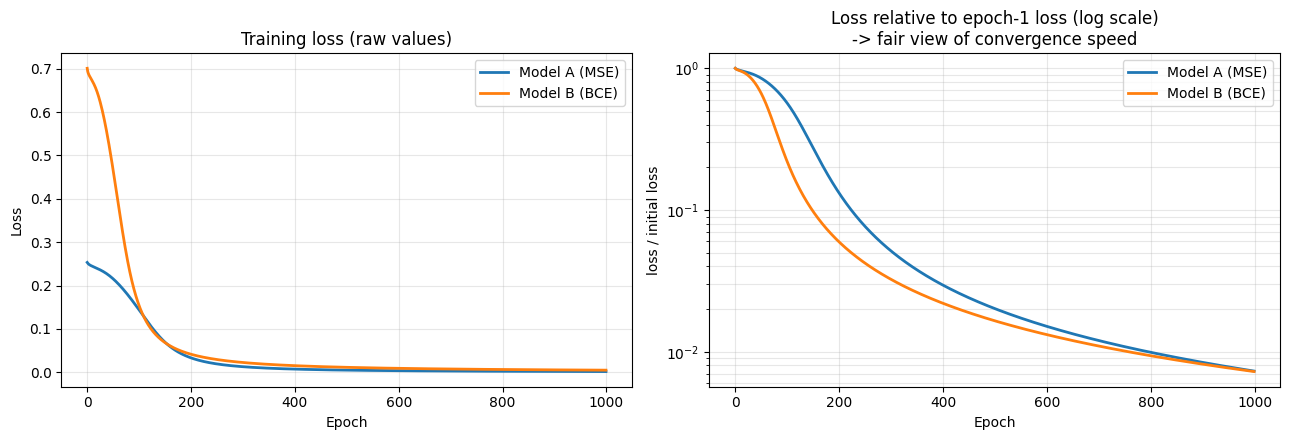

In [18]:
# ---------- Cell 10 : Task 17 – loss curves ----------
lossA = np.array(hist_A.history["loss"]);  lossB = np.array(hist_B.history["loss"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(lossA, linewidth=2, label="Model A (MSE)")
axes[0].plot(lossB, linewidth=2, label="Model B (BCE)")
axes[0].set_title("Training loss (raw values)")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].grid(alpha=0.3); axes[0].legend()

axes[1].plot(lossA / lossA[0], linewidth=2, label="Model A (MSE)")
axes[1].plot(lossB / lossB[0], linewidth=2, label="Model B (BCE)")
axes[1].set_yscale("log")
axes[1].set_title("Loss relative to epoch-1 loss (log scale)\n-> fair view of convergence speed")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("loss / initial loss"); axes[1].grid(alpha=0.3, which="both"); axes[1].legend()

plt.tight_layout(); plt.show()

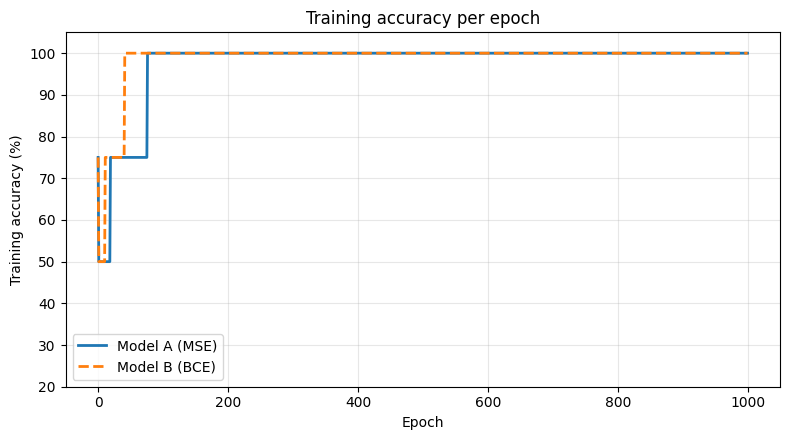

In [19]:
# ---------- Cell 11 : Task 17 – accuracy curves ----------
accA = np.array(hist_A.history["accuracy"]) * 100
accB = np.array(hist_B.history["accuracy"]) * 100

plt.figure(figsize=(8, 4.5))
plt.plot(accA, linewidth=2, label="Model A (MSE)")
plt.plot(accB, linewidth=2, linestyle="--", label="Model B (BCE)")
plt.xlabel("Epoch"); plt.ylabel("Training accuracy (%)"); plt.ylim(20, 105)
plt.title("Training accuracy per epoch"); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.show()

In [20]:
# ---------- Cell 12 : Task 17 – robustness check over 5 different random seeds (optional, ~2-3 min) ----------
# A single run can be lucky or unlucky, so repeat with several initialisations.
seed_rows = []
for s in [0, 1, 2, 3, 4]:
    row = {"Seed": s}
    for label, loss_name in [("MSE", "mean_squared_error"), ("BCE", "binary_crossentropy")]:
        m = build_model(loss_name, seed=s)
        h = m.fit(X, y, epochs=400, batch_size=4, verbose=0)
        row[f"Epochs to 100% acc ({label})"] = epochs_to(h.history["accuracy"], lambda a: a >= 1.0)
        row[f"Final loss ({label})"] = h.history["loss"][-1]
    seed_rows.append(row)

seed_df = pd.DataFrame(seed_rows).set_index("Seed")
display(seed_df)
cols = ["Epochs to 100% acc (MSE)", "Epochs to 100% acc (BCE)"]
print("\nAverage epochs to reach 100% accuracy (runs that did):")
print(seed_df[cols].mean().round(1).to_string())

,Epochs to 100% acc (MSE),Final loss (MSE),Epochs to 100% acc (BCE),Final loss (BCE)
Seed,,,,
0,141,0.0107,75,0.0168
1,99,0.0088,54,0.0152
2,348,0.0780,241,0.0374
3,121,0.0090,67,0.0137
4,161,0.0104,85,0.0172



Average epochs to reach 100% accuracy (runs that did):
Epochs to 100% acc (MSE)   174.0000
Epochs to 100% acc (BCE)   104.4000


In [21]:
# ---------- Cell 13 : auto-generated conclusion text (copy this into the Word report) ----------
fmt = lambda v: "never" if v is None else str(v)
faster = "BCE" if (sum_B["Epochs to 100% accuracy"] or 10**9) < (sum_A["Epochs to 100% accuracy"] or 10**9) else "MSE"

conclusion = f'''
In this experiment, Mean Squared Error (MSE) and Binary Cross Entropy (BCE) were compared for binary
classification. Hand calculations on the first set of predictions gave MSE = {mse_A:.4f} and BCE = {bce_A:.4f};
for the less confident second set they rose to MSE = {mse_B:.4f} and BCE = {bce_B:.4f}, showing that both losses
penalise uncertain predictions, with BCE penalising them more strongly in absolute terms.
Two identical networks (2-4-1, tanh hidden layer, sigmoid output, SGD with learning rate {LR}) were trained on the
XOR problem for {EPOCHS} epochs from the same initial weights. Model A (MSE) finished with a training loss of
{sum_A["Final training loss"]:.4f} and {sum_A["Final accuracy (%)"]:.0f}% accuracy, reaching 100% accuracy after {fmt(sum_A["Epochs to 100% accuracy"])} epochs.
Model B (BCE) finished with a training loss of {sum_B["Final training loss"]:.4f} and {sum_B["Final accuracy (%)"]:.0f}% accuracy, reaching
100% accuracy after {fmt(sum_B["Epochs to 100% accuracy"])} epochs. {faster} therefore converged faster in this run. This agrees with the gradient analysis in
Task 15: for a sigmoid output the BCE gradient is (a - y), whereas the MSE gradient carries the extra factor a(1-a)
that shrinks when the neuron saturates. Raw loss values of the two functions are on different scales and should not be
compared directly; convergence speed and accuracy are the fair comparison. Hence BCE is the preferred loss for
classification, while MSE remains better suited to regression.
'''
print(conclusion.strip())

In this experiment, Mean Squared Error (MSE) and Binary Cross Entropy (BCE) were compared for binary
classification. Hand calculations on the first set of predictions gave MSE = 0.0356 and BCE = 0.1841;
for the less confident second set they rose to MSE = 0.1812 and BCE = 0.5543, showing that both losses
penalise uncertain predictions, with BCE penalising them more strongly in absolute terms.
Two identical networks (2-4-1, tanh hidden layer, sigmoid output, SGD with learning rate 0.5) were trained on the
XOR problem for 1000 epochs from the same initial weights. Model A (MSE) finished with a training loss of
0.0018 and 100% accuracy, reaching 100% accuracy after 77 epochs.
Model B (BCE) finished with a training loss of 0.0051 and 100% accuracy, reaching
100% accuracy after 42 epochs. BCE therefore converged faster in this run. This agrees with the gradient analysis in
Task 15: for a sigmoid output the BCE gradient is (a - y), whereas the MSE gradient carries the extra factor a(1-a)
tha